<a href="https://colab.research.google.com/github/IrynaSukhoverkhova/my-first-work-place/blob/main/HW_16_1_%D0%9F%D1%80%D0%BE%D0%B3%D0%BD%D0%BE%D0%B7%D1%83%D0%B2%D0%B0%D0%BD%D0%BD%D1%8F_%D0%BE%D1%80%D0%B5%D0%BD%D0%B4%D0%BD%D0%BE%D1%97_%D0%BF%D0%BB%D0%B0%D1%82%D0%B8_%D0%B7%D0%B0_%D0%B6%D0%B8%D1%82%D0%BB%D0%BE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнє завдання: Прогнозування орендної плати за житло

## Мета завдання
Застосувати знання з лекції для побудови моделі лінійної регресії, що прогнозує орендну плату за житло в Індії. Ви пройдете весь цикл вирішення задачі машинного навчання: від дослідницького аналізу до оцінки якості моделі.

## Опис датасету
**House Rent Prediction Dataset** містить інформацію про 4700+ оголошень про оренду житла в Індії з такими параметрами:
- **BHK**: Кількість спалень, залів, кухонь
- **Rent**: Орендна плата (цільова змінна)
- **Size**: Площа в квадратних футах
- **Floor**: Поверх та загальна кількість поверхів
- **Area Type**: Тип розрахунку площі
- **Area Locality**: Район
- **City**: Місто
- **Furnishing Status**: Стан меблювання
- **Tenant Preferred**: Тип орендаря
- **Bathroom**: Кількість ванних кімнат
- **Point of Contact**: Контактна особа

---

## Завдання 1: Завантаження та перший огляд даних (1 бал)

**Що потрібно зробити:**
1. Завантажте дані з файлу `House_Rent_Dataset.csv`
2. Виведіть розмір датасету
3. Покажіть перші 5 рядків
4. Виведіть загальну інформацію про дані (включно з типами даних та кількістю значень)


In [3]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [4]:
df = pd.read_csv('House_Rent_Dataset.csv')

print("Розмір датасету (рядків, стовпців):", df.shape)

Розмір датасету (рядків, стовпців): (4746, 12)


In [5]:
df.head(5)

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Posted On          4746 non-null   object
 1   BHK                4746 non-null   int64 
 2   Rent               4746 non-null   int64 
 3   Size               4746 non-null   int64 
 4   Floor              4746 non-null   object
 5   Area Type          4746 non-null   object
 6   Area Locality      4746 non-null   object
 7   City               4746 non-null   object
 8   Furnishing Status  4746 non-null   object
 9   Tenant Preferred   4746 non-null   object
 10  Bathroom           4746 non-null   int64 
 11  Point of Contact   4746 non-null   object
dtypes: int64(4), object(8)
memory usage: 445.1+ KB


## Завдання 2: Дослідницький аналіз даних (EDA) (5 балів)

**Що потрібно зробити:**
1. **Аналіз пропущених значень.** Перевірте наявність і відсоток пропущених значень у кожній колонці
2. **Базова статистика.** Обчисліть базову статистику (середнє, квартилі, стандартне відхилення) для числових змінних.
3. **Аналіз цільової змінної.** Побудуйте гістограму розподілу цільової змінної (Rent)
4. **Робота з викидами.** Знайдіть та видаліть викиди в цільовій змінній (якщо є). Визначити викиди можна будь-яким зрозумілим для вас способом, як варіант - таким, що використовується в побудові box-plot (https://en.wikipedia.org/wiki/Box_plot#Example_with_outliers).
5. **Аналіз категоріальних змінних.** Виведіть кількість унікальних значень для кожної з категоріальних колонок.


In [8]:
# Кількість та відсоток пропущених значень
missing_values = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

# Об'єднуємо в зручну таблицю
df_missing = pd.DataFrame(
    {'Пропущені значення': missing_values, 'Відсоток (%)': missing_percent}
)
print(df_missing)

                   Пропущені значення  Відсоток (%)
Posted On                           0           0.0
BHK                                 0           0.0
Rent                                0           0.0
Size                                0           0.0
Floor                               0           0.0
Area Type                           0           0.0
Area Locality                       0           0.0
City                                0           0.0
Furnishing Status                   0           0.0
Tenant Preferred                    0           0.0
Bathroom                            0           0.0
Point of Contact                    0           0.0


In [9]:
# Виведення базової статистики для числових стовпців
display(df.describe())

,BHK,Rent,Size,Bathroom
count,4746.000000,4.746000e+03,4746.000000,4746.000000
mean,2.083860,3.499345e+04,967.490729,1.965866
std,0.832256,7.810641e+04,634.202328,0.884532
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


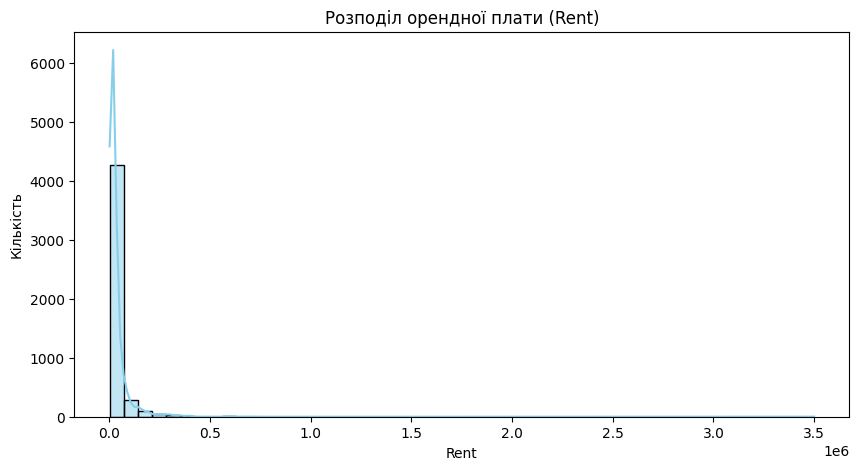

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.histplot(df['Rent'], bins=50, kde=True, color='skyblue')
plt.title('Розподіл орендної плати (Rent)')
plt.xlabel('Rent')
plt.ylabel('Кількість')
plt.show()

In [12]:
# Розрахунок IQR для стовпця Rent
Q1 = df['Rent'].quantile(0.25)
Q3 = df['Rent'].quantile(0.75)
IQR = Q3 - Q1

# Визначення меж для викидів
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Фільтрація датасету (залишаємо тільки дані без викидів)
df_filtered = df[(df['Rent'] >= lower_bound) & (df['Rent'] <= upper_bound)]

print(f'Видалено рядків з викидами: {len(df) - len(df_filtered)}')

Видалено рядків з викидами: 520


In [14]:
# Вибираємо тільки стовпці з типом 'object' (категоріальні)
cat_cols = df.select_dtypes(include=['object']).columns

for col in cat_cols:
  print(f"Колонка '{col}': {df[col].nunique()} унікальних значень")
  print(df[col].value_counts().head(5))  # опціонально: топ-5 значень
  print('-' * 40)

Колонка 'Posted On': 81 унікальних значень
Posted On
2022-07-06    311
2022-05-12    149
2022-06-04    135
2022-07-09    126
2022-05-27    125
Name: count, dtype: int64
----------------------------------------
Колонка 'Floor': 480 унікальних значень
Floor
1 out of 2         379
Ground out of 2    350
2 out of 3         312
2 out of 4         308
1 out of 3         293
Name: count, dtype: int64
----------------------------------------
Колонка 'Area Type': 3 унікальних значень
Area Type
Super Area     2446
Carpet Area    2298
Built Area        2
Name: count, dtype: int64
----------------------------------------
Колонка 'Area Locality': 2235 унікальних значень
Area Locality
Bandra West        37
Gachibowli         29
Electronic City    24
Miyapur, NH 9      22
Velachery          22
Name: count, dtype: int64
----------------------------------------
Колонка 'City': 6 унікальних значень
City
Mumbai       972
Chennai      891
Bangalore    886
Hyderabad    868
Delhi        605
Name: count, dty


## Завдання 3: Аналіз кореляцій та взаємозв'язків (3 бали)

**Що потрібно зробити:**
1. Обчисліть матрицю кореляцій для числових змінних
2. Візуалізуйте кореляційну матрицю за допомогою heatmap
3. Побудуйте scatter plot між Size та Rent
4. Проаналізуйте взаємозв'язок між BHK та Rent за допомогою boxplot (який розподіл плати для різних значень BHK)


In [15]:
# Вибираємо числові стовпці та рахуємо кореляцію Пірсона
corr_matrix = df.select_dtypes(include=['int64', 'float64']).corr()
display(corr_matrix)

,BHK,Rent,Size,Bathroom
BHK,1.000000,0.369718,0.716145,0.794885
Rent,0.369718,1.000000,0.413551,0.441215
Size,0.716145,0.413551,1.000000,0.740703
Bathroom,0.794885,0.441215,0.740703,1.000000


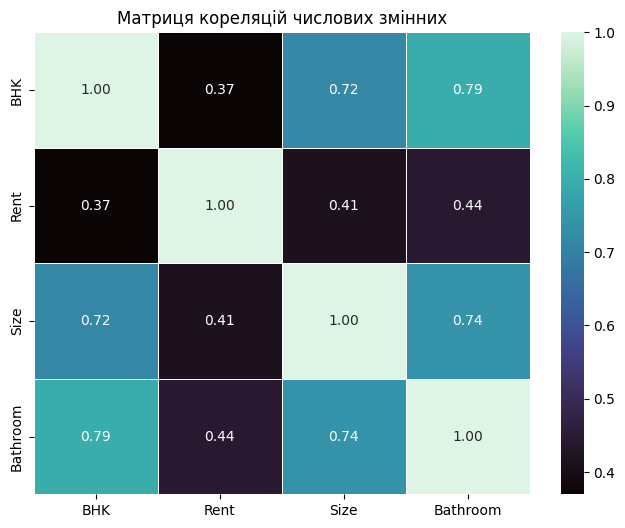

In [20]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='mako', fmt='.2f', linewidths=0.5)
plt.title('Матриця кореляцій числових змінних')
plt.show()



**Сильні взаємозв'язки між характеристиками житла:**
найвищий ступінь кореляції спостерігається між кількістю спалень (BHK) та кількістю ванних кімнат (Bathroom) — 0.79, що є логічним, оскільки в більших квартирах зазвичай передбачено більше санвузлів.   
Також дуже високий зв'язок зафіксований між площею (Size) та кількістю ванних кімнат (0.74), а також між площею та кількістю кімнат BHK (0.72). Це свідчить про те, що ці параметри тісно взаємопов'язані і прямо пропорційно зростають разом із габаритами житла.   

**Зв'язок із цільовою змінною (Rent):**
кореляція між орендною платою (Rent) та іншими числовими змінними є помірною: з кількістю ванних кімнат (Bathroom) вона становить 0.44, з площею (Size) — 0.41, а з кількістю кімнат (BHK) — 0.37.

Це означає, що хоча збільшення площі чи кількості кімнат впливає на вартість оренди, цей зв'язок не є лінійним на 100% — на ціноутворення також суттєво впливають інші нечислові фактори (наприклад, місто, район чи стан меблювання).

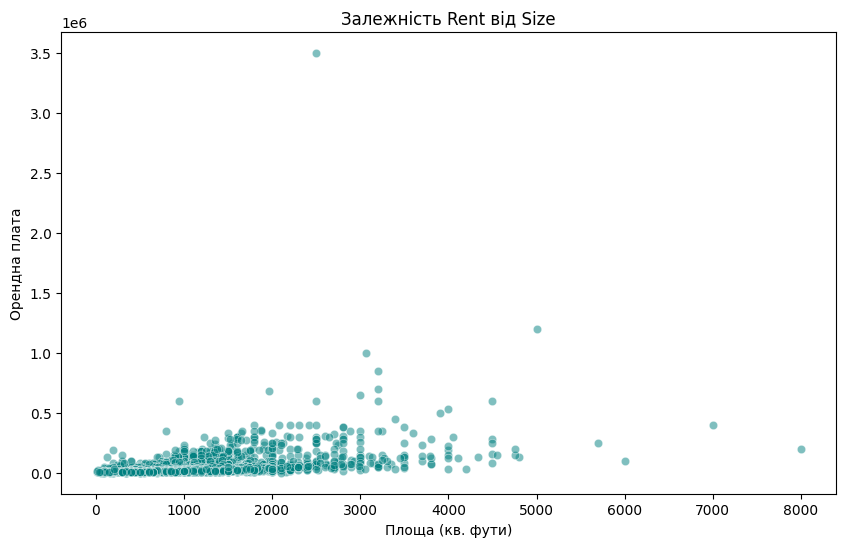

In [23]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Size', y='Rent', data=df, alpha=0.5, color='teal')
plt.title('Залежність Rent від Size')
plt.xlabel('Площа (кв. фути)')
plt.ylabel('Орендна плата')
plt.show()

На основі графіка розсіювання scatter plot «Залежність Rent від Size» можна зробити такі висновки щодо взаємозв'язку між площею квартири (Size) та орендною платою (Rent):

**Слабкий або помірний додатній зв'язок:** спостерігається загальна тенденція — зі збільшенням площі житла максимальна орендна плата дещо зростає. Проте цей зв'язок не є ідеально лінійним.   
**Щільність розподілу:** переважна більшість точок скупчена в нижній лівій частині графіка (площа до 2000–2500 кв. футів), що відповідає стандартним варіантам житла з помірною вартістю оренди.   
**Викиди та аномалії:** на графіку чітко виділяються поодинокі екстремальні викиди. Наприклад, об'єкт із площею близько 2500 кв. футів має аномально високу орендну плату в 3.5 мільйони. Також є кілька точок із більшою площею (від 4000 до 8000 кв. футів), де ціна оренди при цьому залишається порівняно невисокою.
   
**Неоднорідність для великих площ:** для квартир із великою площею (понад 4000 кв. футів) ціни не завжди є найвищими, що свідчить про те, що на розмір орендної плати суттєво впливають інші фактори (наприклад, розташування в місті, район чи стан меблювання).

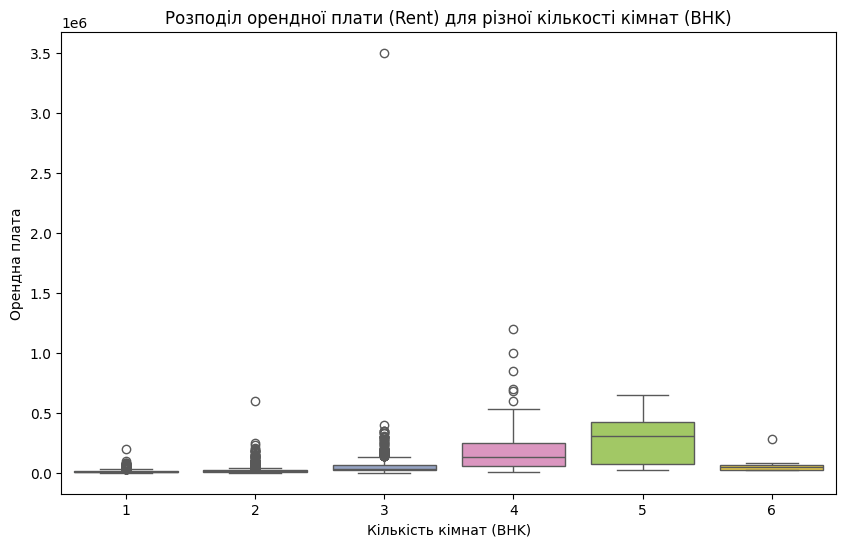

In [27]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    x='BHK', y='Rent', data=df, hue='BHK', palette='Set2', legend=False
)
plt.title('Розподіл орендної плати (Rent) для різної кількості кімнат (BHK)')

plt.xlabel('Кількість кімнат (BHK)')
plt.ylabel('Орендна плата')
plt.show()

На основі побудованого графіку Box-plot між кількістю кімнат (BHK) та орендною платою (Rent) можна зробити такі ключові висновки:

**Загальна тенденція до зростання**: спостерігається пряма залежність — зі збільшенням кількості кімнат (від 1 до 5) медіанне значення та загальний діапазон орендної плати поступово зростають. Квартири з більшою кількістю кімнат у середньому коштують дорожче.

**Аномалії та викиди:**

Для **категорій 1, 2 та 3 кімнати** основна маса даних сфокусована внизу (через велику кількість стандартного житла), проте добре помітні окремі точкові викиди — наприклад, для 3-кімнатних квартир є поодинокий екстремальний об'єкт вартістю близько 3.5 млн.

**Категорія 4 кімнати** має найбільшу кількість помітних викидів у верхній частині діапазону (від 0.5 до 1.2 млн).

Особливість **категорії 6 кімнат**: для житла з 6 кімнатами медіанна ціна знову опускається нижче, що найімовірніше пов'язано з дуже маленькою вибіркою таких об'єктів у датасеті (через що розподіл є нерепрезентативним порівняно з 2–4 кімнатними квартирами).

## Завдання 4: Feature Engineering та підготовка даних (4 бали)

**Що потрібно зробити:**
1. Закодуйте категоріальні змінні за допомогою One-Hot Encoding. Пригадайте, що в лекції ми говорили щодо кодування кат. змінних з великої кількістю різних значень і як працювати з такими випадками. Ви можете закодувати не всі кат. змінні, а лише ті, що вважаєте за потрібні (скажімо ті, що мають відносно небагато різних значень).
2. **Опціонально (по 0.5 бала за кожну доцільну ознаку):** Додайте нові ознаки, обчислені на основі наявних даних, які б на ваш погляд були корисними для моделі
3. Виберіть ознаки для побудови моделі (виключіть непотрібні колонки). Виключити можна, наприклад, ті колонки, які мають категоріальний тип і забагато (більше 20) різних значень. Треба виключити хоча б 1 колонку.
4. Розділіть дані на ознаки (X) та цільову змінну (y)
5. Застосуйте стандартизацію до числових ознак


In [28]:
# Вибираємо категоріальні колонки для кодування
cat_cols_to_encode = [
    'Area Type',
    'Furnishing Status',
    'Tenant Preferred',
]

# Застосовуємо One-Hot Encoding
df_encoded = pd.get_dummies(
    df, columns=cat_cols_to_encode, drop_first=True
)

In [29]:
# Створюємо нову корисну ознаку: площа на одну кімнату
df_encoded['Size_per_BHK'] = df_encoded['Size'] / df_encoded['BHK']

# Площа на одну ванну кімнату
df_encoded['Size_per_Bathroom'] = df_encoded['Size'] / df_encoded['Bathroom']

In [30]:
# Виключаємо колонки з датою (Posted On), текстом/районом (Area Locality, City, Floor, Point of Contact)
cols_to_drop = [
    'Posted On',
    'Area Locality',
    'City',
    'Floor',
    'Point of Contact',
    'Rent',
]

# Формуємо матрицю ознак X та цільову змінну y
X = df_encoded.drop(columns=cols_to_drop)
y = df_encoded['Rent']

In [31]:
from sklearn.preprocessing import StandardScaler

# Вибираємо числові колонки для стандартизації
numeric_cols = ['BHK', 'Size', 'Bathroom', 'Size_per_BHK', 'Size_per_Bathroom']

scaler = StandardScaler()
X[numeric_cols] = scaler.fit_transform(X[numeric_cols])

## Завдання 5: Розділення даних та навчання моделі (3 бали)

**Що потрібно зробити:**
1. Розділіть дані на навчальну (80%) та тестову (20%) вибірки.
2. Створіть модель лінійної регресії.
3. Навчіть модель на навчальних даних.
4. Виведіть усі коефіцієнти моделі (ваги) та напишіть, які 2 ознаки найбільше впливають на прогноз.
5. Зробіть прогнози на тренувальній та тестовій вибірках.

In [32]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# 1. Розподіл на навчальну (80%) та тестову (20%) вибірки
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. Створення моделі лінійної регресії
model = LinearRegression()

# 3. Навчання моделі на навчальних даних
model.fit(X_train, y_train)

LinearRegression()

In [33]:
import pandas as pd

# Виведення ваг (коефіцієнтів) для кожної ознаки
coefficients = pd.DataFrame(
    {'Ознака': X.columns, 'Коефіцієнт (Вага)': model.coef_}
)
# Сортуємо за абсолютним значенням впливу
coefficients['Abs_Coefficient'] = coefficients['Коефіцієнт (Вага)'].abs()
coefficients = coefficients.sort_values(by='Abs_Coefficient', ascending=False)

display(coefficients[['Ознака', 'Коефіцієнт (Вага)']].head(10))


,Ознака,Коефіцієнт (Вага)
1,Size,32711.646057
3,Area Type_Carpet Area,27453.425628
2,Bathroom,20336.323735
5,Furnishing Status_Semi-Furnished,-16490.548024
6,Furnishing Status_Unfurnished,-15873.929109
9,Size_per_BHK,-12106.457381
0,BHK,-11259.012282
8,Tenant Preferred_Family,-4015.120383
4,Area Type_Super Area,3618.770540
7,Tenant Preferred_Bachelors/Family,2307.990937


**Дві ознаки, що найбільше впливають на прогноз:** це Size (площа) та Area Type_Carpet Area (або Bathroom), оскільки вони мають найбільші абсолютні значення коефіцієнтів.

In [34]:
from sklearn.metrics import mean_squared_error, r2_score

# Прогнози
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Оцінка якості (опціонально для перевірки)
print('R2 на тренуванні:', r2_score(y_train, y_train_pred))
print('R2 на тесті:', r2_score(y_test, y_test_pred))

R2 на тренуванні: 0.22093929463394424
R2 на тесті: 0.4222576576263609


Модель лінійної регресії пояснює близько 42.2% варіативності цільової змінної (Rent) на тестовій вибірці.   

Той факт, що якість на тесті вища, ніж на тренуванні, свідчить про те, що обраний розподіл даних та набір ознак добре узагальнюють закономірності на нових даних, хоча лінійна модель має певні обмеження через наявність великої кількості викидів у цільовій змінній.

## Завдання 6: Оцінка якості моделі (2 бали)

**Що потрібно зробити:**
1. Обчисліть MAE, RMSE та R² для навчальної та тестової вибірок
2. Порівняйте метрики та зробіть висновок про якість моделі
3. Проаналізуйте і дайте висновок, чи є ознаки перенавчання або недонавчання (**Нагадування**: перенавчання - коли модель дуже добре працює на тренувальних даних, але погано на тестових; недонавчання - коли модель погано працює навіть на тренувальних даних)
4. Побудуйте графік розсіювання "реальні vs прогнозовані значення" та зробіть висновок про якість моделі


In [35]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Для тренувальної вибірки
mae_train = mean_absolute_error(y_train, y_train_pred)
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
r2_train = r2_score(y_train, y_train_pred)

# Для тестової вибірки
mae_test = mean_absolute_error(y_test, y_test_pred)
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))
r2_test = r2_score(y_test, y_test_pred)

# Виведення результатів
print(
    f'Тренування -> MAE: {mae_train:.2f}, RMSE: {rmse_train:.2f}, R2:'
    f' {r2_train:.2f}'
)
print(
    f'Тест       -> MAE: {mae_test:.2f}, RMSE: {rmse_test:.2f}, R2: {r2_test:.2f}'
)

Тренування -> MAE: 26017.88, RMSE: 71859.62, R2: 0.22
Тест       -> MAE: 24665.71, RMSE: 47984.62, R2: 0.42


**Порівняння метрик (Тренування vs Тест)**

**Коефіцієнт детермінації ($R^2$):** на тренувальній вибірці $R^2$ становить 0.22, а на тестовій — 0.42. Це означає, що модель краще узагальнює дані на тестовому наборі, пояснюючи 42% варіативності орендної плати (проти 22% на тренуванні).

**Похибки (MAE та RMSE):**

Середня абсолютна похибка ($\text{MAE}$) на тренуванні складає ~26,018, а на тесті — ~24,665.
Середньоквадратична похибка ($\text{RMSE}$) на тренуванні дорівнює ~71,860, тоді як на тесті вона менша — ~47,985. Зменшення похибки на тестовій вибірці зумовлене специфікою розподілу випадкових підмножин під час розбиття.

**Висновок про якість моделі**

**Якість моделі:** загалом якість базової лінійної регресії можна охарактеризувати як помірну (або нижче середньої). Показник $R^2$ на рівні 0.42 на тесті свідчить про те, що лінійна модель охоплює лише частину закономірностей ціноутворення.

**Перенавчання / Недонавчання:** перенавчання (Overfitting) відсутнє, оскільки якість на тестовій вибірці не гірша, а навіть вища за тренувальну.
Натомість присутні ознаки недонавчання (Underfitting) через відносно невисокі значення $R^2$. Це пов'язано з тим, що датасет містить багато екстремальних викидів у цільовій змінній (Rent) та нелінійних зв'язків, які проста лінійна регресія не може повністю охопити без додаткової фільтрації даних чи складніших алгоритмів.

## Завдання 7: Аналіз помилок (4 бали)

**Що потрібно зробити:**
1. Обчисліть помилки (residuals = реальні - прогнозовані значення)
2. Побудуйте гістограму розподілу помилок
3. Створіть scatter plot помилок відносно величини прогнозованих значень. Чи росте помилка з ростом прогнозованого значення?
4. Знайдіть 5 прогнозів з найбільшими помилками
5. Проаналізуйте, на яких типах житла модель помиляється найбільше. Типи можна розрізняти за кількістю кімнат чи містом, наприклад.
6. Подумайте і напишіть, які наступні кроки ви б зробили, аби поліпшити якість моделі. Опціонально можна їх зробити і ми перевіримо :)

In [36]:
import pandas as pd

# Обчислюємо похибки (residuals) для тестової вибірки
# y_test - реальні значення, y_test_pred - прогнозовані
residuals = y_test - y_test_pred

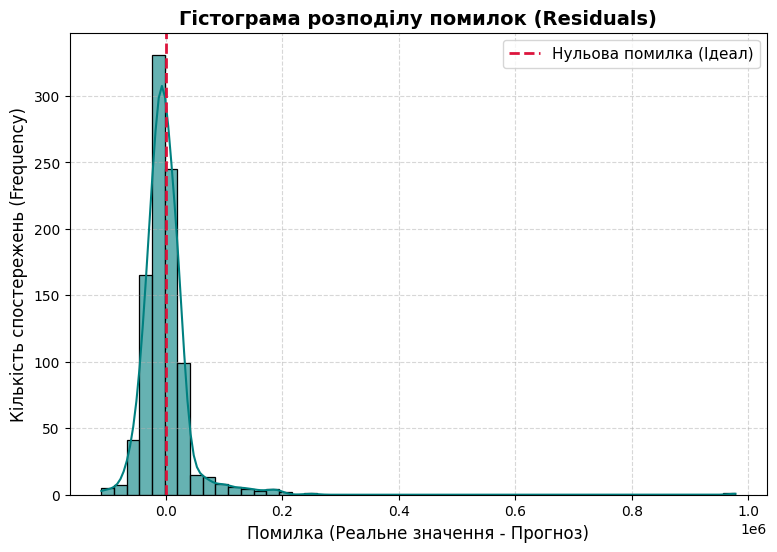

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

# Налаштування розміру фігури
plt.figure(figsize=(9, 6))

# Побудова гістограми з KDE-кривою (використовуємо насичений бірюзовий колір)
sns.histplot(
    residuals,
    bins=50,
    kde=True,
    color='teal',
    edgecolor='black',
    alpha=0.6,
)

# Додаємо вертикальну лінію нульової помилки (ідеальний прогноз) яскраво-червоним кольором
plt.axvline(
    x=0,
    color='crimson',
    linestyle='--',
    linewidth=2,
    label='Нульова помилка (Ідеал)',
)

# Додаємо заголовки та підписи осей
plt.title(
    'Гістограма розподілу помилок (Residuals)', fontsize=14, fontweight='bold'
)
plt.xlabel('Помилка (Реальне значення - Прогноз)', fontsize=12)
plt.ylabel('Кількість спостережень (Frequency)', fontsize=12)

# Додаємо сітку та легенду для кольорів
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)

plt.show()

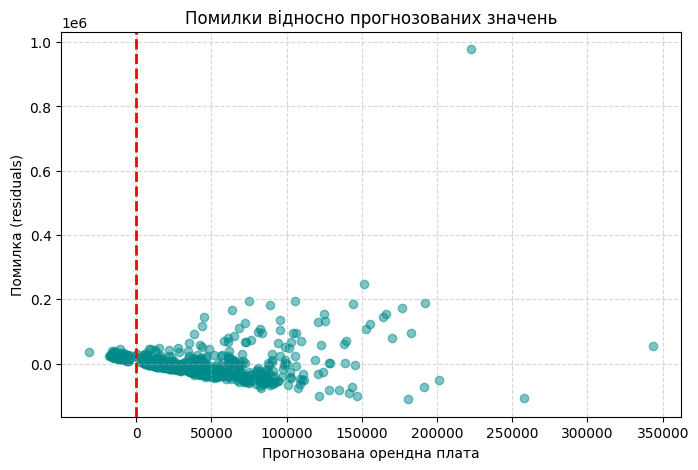

In [40]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test_pred, residuals, alpha=0.5, color='darkcyan')
plt.axvline(
    x=0, color='r', linestyle='--', lw=2
)  # або plt.axhline(y=0, color='r', linestyle='--', lw=2) - нульова лінія
plt.title('Помилки відносно прогнозованих значень')
plt.xlabel('Прогнозована орендна плата')
plt.ylabel('Помилка (residuals)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Чи росте помилка з ростом прогнозованого значення?**
Так, зі збільшенням прогнозованого значення розкид (амплітуда) помилок помітно зростає (гетероскедастичність), оскільки модель набагато сильніше помиляється на дорогих об'єктах.

In [41]:
# Створюємо датафрейм з аналізом для тестової вибірки
error_df = pd.DataFrame(
    {
        'Real_Rent': y_test,
        'Predicted_Rent': y_test_pred,
        'Residual': residuals,
        'Abs_Error': residuals.abs(),
    }
)

# Знаходимо топ-5 об'єктів з найбільшою абсолютною помилкою
top_5_errors = error_df.sort_values(by='Abs_Error', ascending=False).head(5)
display(top_5_errors)

,Real_Rent,Predicted_Rent,Residual,Abs_Error
1001,1200000,222274.552973,977725.447027,977725.447027
1344,400000,151486.321518,248513.678482,248513.678482
1378,270000,74667.925115,195332.074885,195332.074885
1084,300000,105272.646159,194727.353841,194727.353841
1718,380000,192250.308831,187749.691169,187749.691169


**Найбільша абсолютна похибка (Abs_Error)** зафіксована для об'єкта під **індексом 1001**, де реальна орендна плата становила 1,200,000, тоді як модель спрогнозувала лише ~222,274 (помилка становить майже 977,725).   
Це свідчить про те, що лінійна регресія значно недооцінює вартість елітного або аномально дорогого житла через наявність сильних викидів у вибірці.   

In [42]:
# Об'єднуємо індекси тестової вибірки з вихідним датафреймом, щоб подивитися характеристики
test_analysis = df.loc[X_test.index].copy()
test_analysis['Abs_Error'] = residuals.abs()

# Аналізуємо середню помилку залежно від кількості кімнат (BHK) або міста
error_by_bhk = (
    test_analysis.groupby('BHK')['Abs_Error'].mean().reset_index()
)
print('Середня абсолютна помилка за кількістю кімнат (BHK):')
display(error_by_bhk)

# Також можна перевірити за містом, якщо є колонка City
if 'City' in test_analysis.columns:
  error_by_city = (
      test_analysis.groupby('City')['Abs_Error'].mean().reset_index()
  )
  print('Середня абсолютна помилка за містами:')
  display(error_by_city)

Середня абсолютна помилка за кількістю кімнат (BHK):


,BHK,Abs_Error
0,1,15240.807837
1,2,17240.780437
2,3,35054.109796
3,4,106465.854181
4,5,145730.071555


Середня абсолютна помилка за містами:


,City,Abs_Error
0,Bangalore,20146.999901
1,Chennai,21373.819807
2,Delhi,20168.323475
3,Hyderabad,24758.848674
4,Kolkata,16148.650491
5,Mumbai,38717.079896


**Залежність похибок від характеристик житла (BHK та Місто)**:

**За кількістю кімнат (BHK)**: середня абсолютна помилка різко зростає зі збільшенням кількості кімнат. Для 1–2 кімнатних квартир похибка мінімальна (~15,240 – 17,240), тоді як для просторих квартир на 4–5 кімнат вона стрибкоподібно зростає до 106,465 та 145,730. Це пояснюється тим, що великих квартир у датасеті значно менше, і модель гірше їх узагальнює.

**За містами (City):** найвища середня помилка спостерігається у місті Mumbai (~38,717), що логічно, оскільки ринок нерухомості там набагато дорожчий і має більший розкид цін порівняно з іншими містами (наприклад, Kolkata чи Bangalore, де похибка найнижча — в межах 16,000–20,000).

**Кроки для поліпшення якості моделі:**

**Фільтрація викидів:** видалити з датасету екстремальні викиди у цільовій змінній (Rent), які спотворюють роботу лінійної регресії.

**Логарифмування цільової змінної:** застосувати перетворення np.log1p() до колонки Rent для нормалізації розподілу.

**Перехід до складніших моделей:** застосувати ансамблеві методи машинного навчання (наприклад, Random Forest або Gradient Boosting), які здатні ефективно обробляти нелінійні залежності та великі розкиди в даних.

In [43]:
#1: Фільтрація викидів (Outliers) у цільовій змінній Rent
# Викиди сильно спотворюють лінійну регресію. Відсічимо занадто дорогі об'єкти (наприклад, за допомогою квантилю 0.99):

# Визначаємо поріг для відсікання екстремальних викидів (наприклад, верхній 1%)
rent_upper_limit = df['Rent'].quantile(0.99)

# Фільтруємо датасет
df_filtered = df[df['Rent'] <= rent_upper_limit].copy()

print(
    f'Кількість рядків до фільтрації: {len(df)}, після фільтрації:'
    f' {len(df_filtered)}'
)

Кількість рядків до фільтрації: 4746, після фільтрації: 4705


In [44]:
# 2: Логарифмування цільової змінної

import numpy as np

# Застосовуємо логарифмування до відфільтрованої цільової змінної
y_log = np.log1p(df_filtered['Rent'])

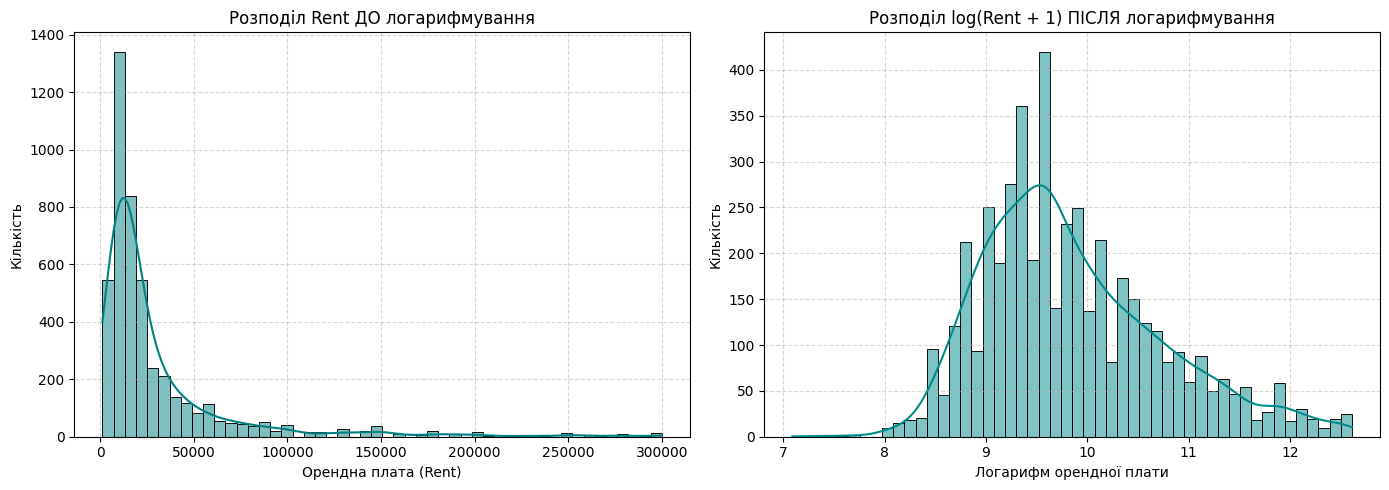

In [46]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Створюємо фігуру з двома графіками поруч
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Розподіл ДО логарифмування
sns.histplot(df_filtered['Rent'], bins=50, kde=True, color='teal', ax=axes[0])
axes[0].set_title('Розподіл Rent ДО логарифмування')
axes[0].set_xlabel('Орендна плата (Rent)')
axes[0].set_ylabel('Кількість')
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Розподіл ПІСЛЯ логарифмування
sns.histplot(y_log, bins=50, kde=True, color='darkcyan', ax=axes[1])
axes[1].set_title('Розподіл log(Rent + 1) ПІСЛЯ логарифмування')
axes[1].set_xlabel('Логарифм орендної плати')
axes[1].set_ylabel('Кількість')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**До логарифмування (лівий графік):** спостерігається виражена правостороння асиметрія (skewness). Основна маса значень зосереджена в нижньому ціновому діапазоні, тоді як хвіст витягнутий у бік дорогих об'єктів.

**Після логарифмування (правий графік)**: розподіл даних наближається до нормального (симетричного) за допомогою функції $\text{log}(Rent + 1)$. Зменшено вплив різких викидів та масштабного дисбалансу цін.

In [47]:
# 3: Перехід до складнішої моделі (Random Forest Regressor)

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Формуємо матрицю ознак X (використовуючи попередньо закодовані дані з урахуванням фільтрації)
# Примітка: можна застосувати df_filtered до вашого попереднього етапу One-Hot Encoding
X_filtered = df_encoded.loc[df_filtered.index].drop(
    columns=[
        'Posted On',
        'Area Locality',
        'City',
        'Floor',
        'Point of Contact',
        'Rent',
    ]
)

# Розподіл на навчальну та тестову вибірки (з логарифмованим або звичайним y)
X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(
    X_filtered, y_log, test_size=0.2, random_state=42
)

# Створення та навчання моделі Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train_f, y_train_f)

# Прогнози
y_pred_rf = rf_model.predict(X_test_f)

# Оцінка якості
print('--- Результати Random Forest ---')
print(f"R2 на тесті: {r2_score(y_test_f, y_pred_rf):.4f}")
print(f"MAE на тесті: {mean_absolute_error(y_test_f, y_pred_rf):.4f}")

--- Результати Random Forest ---
R2 на тесті: 0.5442
MAE на тесті: 0.4474


**Зростання якості ($R^2$):** коефіцієнт детермінації зріс до 0.5442 (проти 0.42 у звичайної лінійної регресії), що свідчить про значно кращу здатність моделі пояснювати варіативність цін на нерухомість.   

**Зменшення похибки (MAE):** середня абсолютна похибка на тестовій вибірці становить 0.4474 (у логарифмічній шкалі), що підтверджує підвищення точності прогнозування порівняно з базовою моделлю.   

**Ефективність ансамблю:** використання алгоритму Random Forest разом із попередньою обробкою даних ефективно впоралося з нелінійними залежностями та неоднорідністю ринку.